In [1]:
pip install opencv-python 'numpy<2' matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

(-0.5, 193.5, 258.5, -0.5)

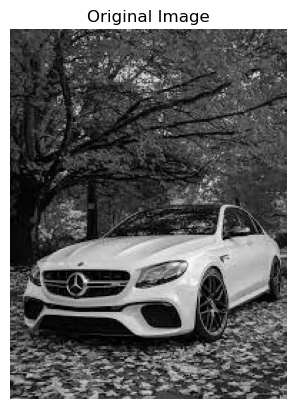

In [7]:
import urllib.request

url = 'https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcT8s6xkPkAxL73Cm1oyFFluXSKT306rBJAg7Q&s'
urllib.request.urlretrieve(url, 'image.png')

image = cv2.imread('image.png')
image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.imshow(image, cmap='gray')
plt.title('Original Image')
plt.axis('off')

(-0.5, 193.5, 258.5, -0.5)

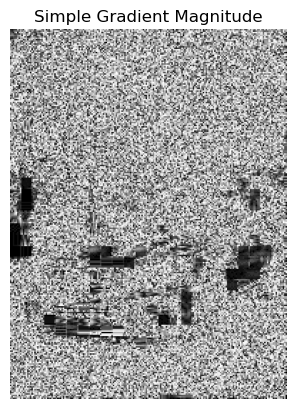

In [9]:
gx = np.zeros_like(image)
gy = np.zeros_like(image)

gx[:, :-1] = np.diff(image, axis=1)
gy[:-1, :] = np.diff(image, axis=0)

gradient_magnitude = np.sqrt(gx**2 + gy**2)

plt.imshow(gradient_magnitude, cmap='gray')
plt.title('Simple Gradient Magnitude')
plt.axis('off')


(-0.5, 193.5, 258.5, -0.5)

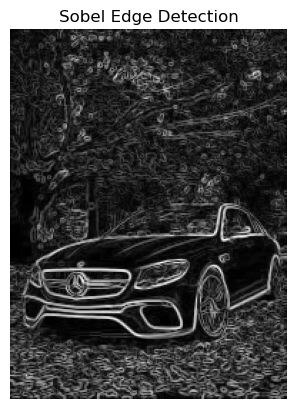

In [11]:
sobel_x = cv2.Sobel(image, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(image, cv2.CV_64F, 0, 1, ksize=3)

sobel_magnitude = np.sqrt(sobel_x**2 + sobel_y**2)

plt.imshow(sobel_magnitude, cmap='gray')
plt.title('Sobel Edge Detection')
plt.axis('off')

(-0.5, 193.5, 258.5, -0.5)

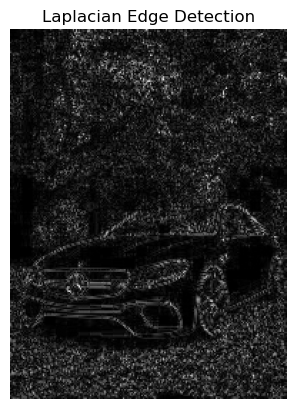

In [13]:
laplacian = cv2.Laplacian(image, cv2.CV_64F)

plt.imshow(np.abs(laplacian), cmap='gray')
plt.title('Laplacian Edge Detection')
plt.axis('off')

(-0.5, 193.5, 258.5, -0.5)

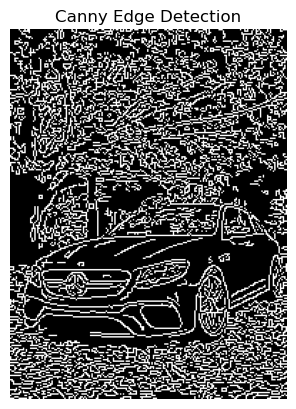

In [14]:
canny = cv2.Canny(image, 100, 200)

plt.imshow(canny, cmap='gray')
plt.title('Canny Edge Detection')
plt.axis('off')


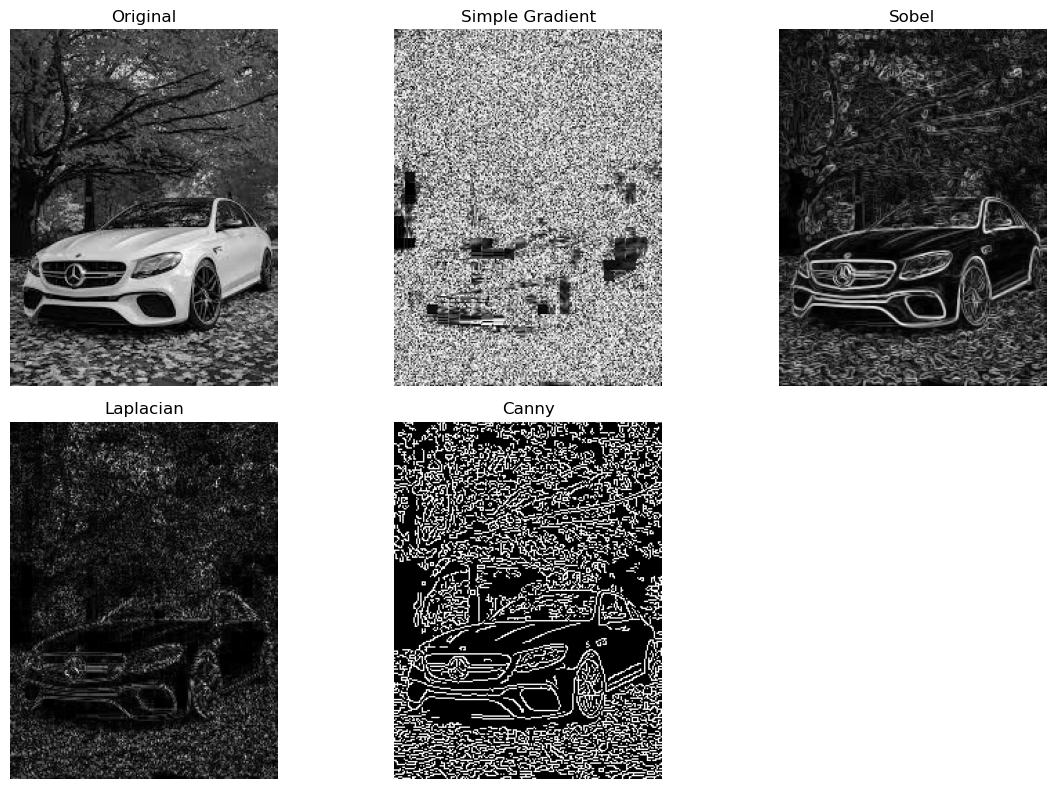

In [16]:
plt.figure(figsize=(12,8))

plt.subplot(2,3,1)
plt.imshow(image, cmap='gray')
plt.title('Original')
plt.axis('off')

plt.subplot(2,3,2)
plt.imshow(gradient_magnitude, cmap='gray')
plt.title('Simple Gradient')
plt.axis('off')

plt.subplot(2,3,3)
plt.imshow(sobel_magnitude, cmap='gray')
plt.title('Sobel')
plt.axis('off')

plt.subplot(2,3,4)
plt.imshow(np.abs(laplacian), cmap='gray')
plt.title('Laplacian')
plt.axis('off')

plt.subplot(2,3,5)
plt.imshow(canny, cmap='gray')
plt.title('Canny')
plt.axis('off')

plt.tight_layout()
plt.show()

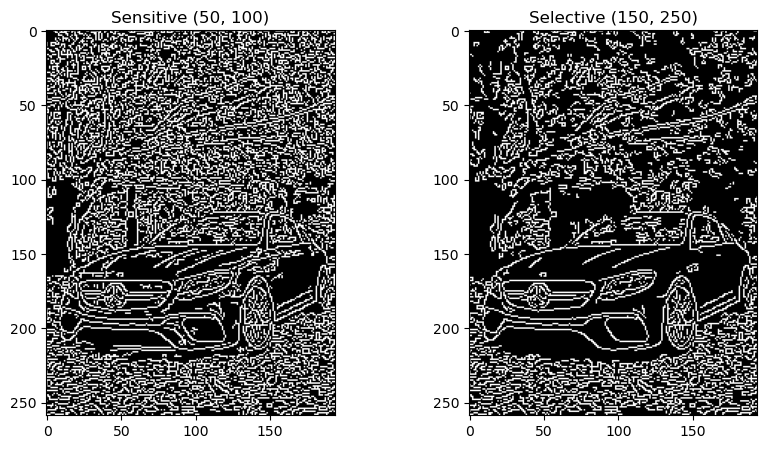

In [17]:
canny_sensitive = cv2.Canny(image, 50, 100)
canny_selective = cv2.Canny(image, 150, 250)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.imshow(canny_sensitive, cmap='gray'), plt.title('Sensitive (50, 100)')
plt.subplot(1, 2, 2), plt.imshow(canny_selective, cmap='gray'), plt.title('Selective (150, 250)')
plt.show()

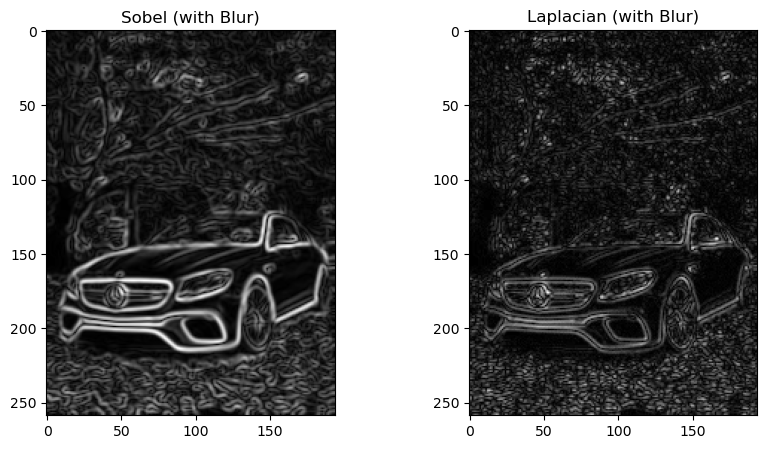

In [18]:
blurred_img = cv2.GaussianBlur(image, (5, 5), 0)

sobel_x = cv2.Sobel(blurred_img, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(blurred_img, cv2.CV_64F, 0, 1, ksize=3)
sobel_combined = cv2.magnitude(sobel_x, sobel_y)

laplacian_blurred = cv2.Laplacian(blurred_img, cv2.CV_64F)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.imshow(sobel_combined, cmap='gray'), plt.title('Sobel (with Blur)')
plt.subplot(1, 2, 2), plt.imshow(np.abs(laplacian_blurred), cmap='gray'), plt.title('Laplacian (with Blur)')
plt.show()